# DL_02 — Building prediction (single-task DL)

**Purpose.** Predict `BUILDINGID` (3 classes) from the 1,040-feature fingerprint.

**Model.** The shared-trunk MLP from `src/signal2space_dl/model.py` with only the **building** head
enabled (`experiment="building_only"`). It is a single-task ablation: comparing it with the multitask model in
DL_05 shows whether sharing a trunk across tasks helps or hurts this target.

**Selection.** Fixed a-priori hyperparameters (`TrainConfig`), early stopping on the
internal-validation loss. The held-out partition is scored only after the checkpoint is frozen; the
evaluation step re-checks the checkpoint SHA-256 recorded at training time.

**Outputs.** `models/dl_02_building_model.pt|json`, `data/tables/dl_02_building_*`, `data/figures/dl_02_building_*`.

In [1]:
import sys
from pathlib import Path

# Locate the repository root whether Jupyter starts in the root or in "Deep Learning Pipeline/".
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "signal2space_dl").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import json, platform
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

from signal2space_dl import config as C, data as D, evaluate as E, plots as P
from signal2space_dl.cli import run_compare, run_evaluate, run_train

paths = C.Paths(ROOT).ensure()
cfg = C.TrainConfig()
pd.set_option("display.width", 160, "display.max_columns", 30)
print(f"Repository: {ROOT}")
print(f"Python {platform.python_version()} | torch {torch.__version__} | pandas {pd.__version__} | NumPy {np.__version__}")

Repository: /home/user/Signal2Space
Python 3.13.18 | torch 2.15.0+cu132 | pandas 3.0.6 | NumPy 2.5.4


In [2]:
data = D.prepare(paths, coord_scale=cfg.coord_scale, save=False)
print({s: len(f) for s, f in data.frames.items()})

{'internal_train': 16085, 'internal_validation': 3852, 'heldout_validation': 1111}


## 1. Train (or reuse the frozen checkpoint)

In [3]:
CHECKPOINT = paths.models / "dl_02_building_model.pt"
RETRAIN = False   # set True to retrain from scratch; the default reuses the committed checkpoint
if RETRAIN or not CHECKPOINT.exists():
    run_train(data, paths, cfg, ["building_only"])
meta = json.loads((paths.models / "dl_02_building_model.json").read_text())
print(json.dumps({k: meta[k] for k in ["tasks", "selected_epoch", "epochs_run", "best_internal_validation_loss",
                                       "n_parameters", "training_seconds", "device", "torch_version"]}, indent=1))

{
 "tasks": [
  "building"
 ],
 "selected_epoch": 13,
 "epochs_run": 28,
 "best_internal_validation_loss": 0.001461162763407893,
 "n_parameters": 699139,
 "training_seconds": 30.0,
 "device": "cpu",
 "torch_version": "2.15.0+cu132"
}


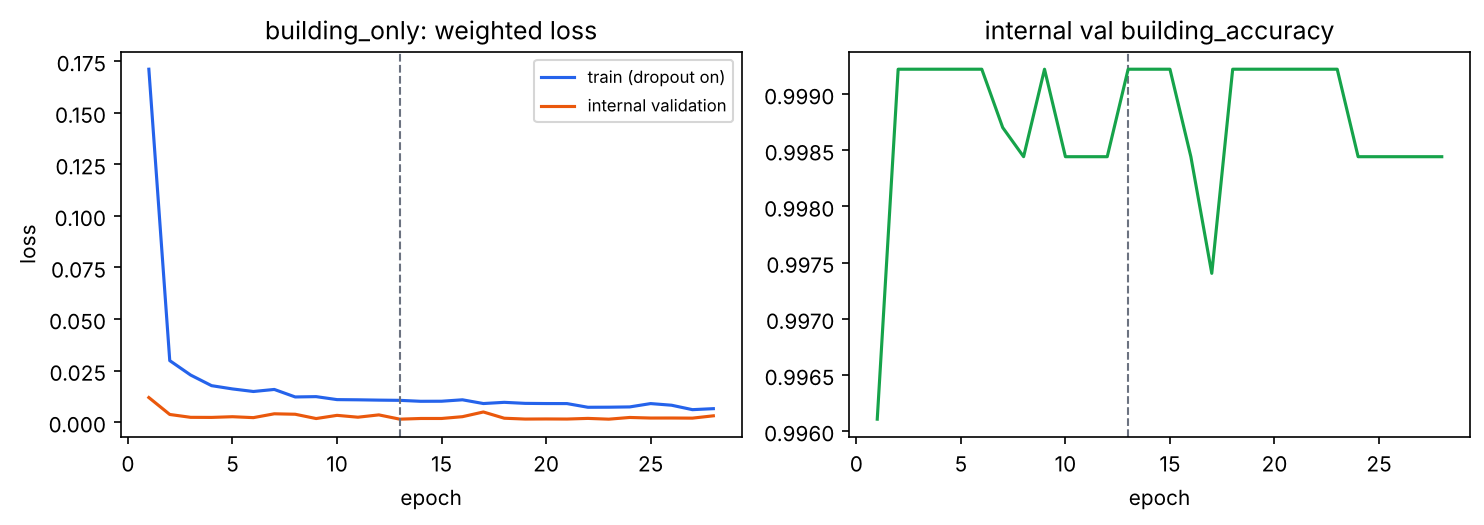

In [4]:
history = pd.read_csv(paths.tables / "dl_02_building_training_history.csv")
P.training_curves(history, paths, "dl_02_building", "building_only")
display(Image(paths.figures / "dl_02_building_training_curves.png"))

## 2. Evaluate the frozen model (internal validation, then held-out)

In [5]:
preds, rows = run_evaluate(data, paths, ["building_only"])
metrics = pd.DataFrame(rows).drop(columns=["checkpoint_sha256"])
display(metrics.round(4))

,model,experiment,split,task,n_rows,selected_epoch,accuracy,macro_f1,balanced_accuracy,n_correct
0,DL building_only,building_only,internal_validation,building,3852,13,0.9992,0.9992,0.9994,3849
1,DL building_only,building_only,heldout_validation,building,1111,13,0.9982,0.9983,0.9988,1109


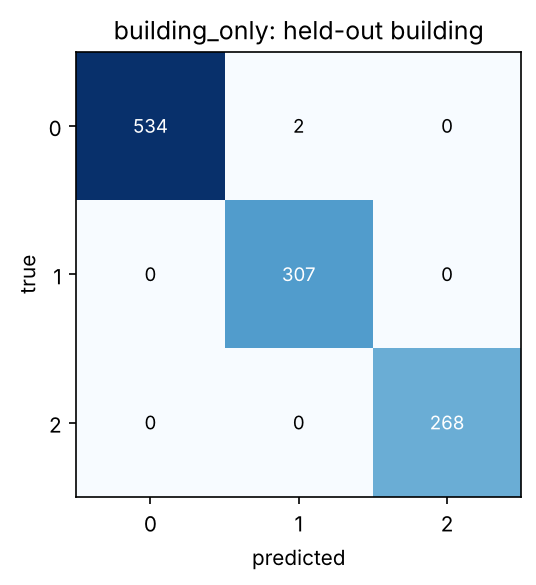

,model,task,class,support,precision,recall,f1
0,DL building_only,building,0,536,1.0000,0.9963,0.9981
1,DL building_only,building,1,307,0.9935,1.0000,0.9968
2,DL building_only,building,2,268,1.0000,1.0000,1.0000


In [6]:
display(Image(paths.figures / "dl_02_building_heldout_confusion_matrix.png"))
display(pd.read_csv(paths.tables / "dl_02_building_heldout_per_class.csv").round(4))

## 3. Same-partition comparison with the AML baseline

In [7]:
aml = pd.DataFrame(E.aml_metric_rows(paths))
cmp = pd.concat([aml[aml.task == "building"], metrics[metrics.task == "building"]], ignore_index=True)
cols = [c for c in ["model", "split", "accuracy", "macro_f1", "balanced_accuracy", "mae_longitude", "mae_latitude",
                    "mean_euclidean_error", "median_euclidean_error", "p90_euclidean_error"] if c in cmp]
display(cmp[cols].round(4))

,model,split,accuracy,macro_f1,balanced_accuracy,mae_longitude,mae_latitude,mean_euclidean_error,median_euclidean_error,p90_euclidean_error
0,AML Random Forest,internal_validation,0.9995,0.9995,0.9994,NaN,NaN,NaN,NaN,NaN
1,AML Random Forest,heldout_validation,0.9973,0.9971,0.9972,NaN,NaN,NaN,NaN,NaN
2,DL building_only,internal_validation,0.9992,0.9992,0.9994,NaN,NaN,NaN,NaN,NaN
3,DL building_only,heldout_validation,0.9982,0.9983,0.9988,NaN,NaN,NaN,NaN,NaN


## Findings

- The frozen building-only model, selected at epoch 13 of 28, gets **99.82%** held-out accuracy (1,109/1,111) with macro F1 99.83%. The AML Random Forest gets 99.73% (1,108/1,111).
- The one-row difference is within noise: the paired bootstrap 95% interval for DL minus AML is [-0.18, +0.36] percentage points.
- Both held-out errors are building-0 rows predicted as building 1. Building is close to saturated for both model families.